# Estudio de Caso Real: Detección y Desconvolución de Adulteración Tóxica en Cúrcuma
## Cuantificación de Incertidumbre en Trazas (LOD/LOQ), Trompeta de Horwitz y Desconvolución Ciega (DPS) en Espectros FT-Raman Reales

---

### Resumen Ejecutivo y Motivación Analítica (Para el Supervisor de Laboratorio)

En los laboratorios analíticos y de control de calidad bajo normativas **ISO/IEC 17025**, directrices de la **FDA/EMA** y la **Farmacopea**, la cuantificación multivariante mediante métodos clásicos (**PLS / PCR**) y redes neuronales deterministas enfrenta dos límites conceptuales y metrológicos insalvables:

1. **La Crisis Metrológica cerca del Límite de Cuantificación (LOD / LOQ):**
   * En análisis cuantitativo de trazas (contaminantes o impurezas a nivel sub-ppm/ppb), la concentración es una magnitud física estrictamente no negativa ($y \ge 0$) con varianza heterocedástica (Trompeta de Horwitz).
   * Los modelos lineales asumen errores gaussianos simétricos y homocedásticos ($\pm t_{\alpha/2} \cdot s_{\text{pred}}$). Cerca de cero, esto genera la **aberración metrológica de predecir límites inferiores negativos**, violando la física fundamental, la **GUM** (*Guide to the Expression of Uncertainty in Measurement*) y las normas **ISO 11843**.
2. **El Fallo Silencioso ante Adulterantes e Interferentes No Modelados:**
   * Cuando una muestra real contiene un interferente o adulterante extraño, **PLS proyecta ciegamente la señal sobre el vector de regresión**, entregando un resultado fuertemente sesgado con una falsa apariencia de precisión y sin alertar al analista.

### El Caso de Estudio: Cromato de Plomo ($PbCrO_4$) en Cúrcuma en Polvo

Este notebook aplica el framework de **Quimiometría Generativa Basada en Modelos de Difusión** sobre un conjunto de datos espectroscópicos reales publicado por **Erasmus et al. (Food Control, 2021; DOI: [10.1016/j.foodcont.2020.107714](https://doi.org/10.1016/j.foodcont.2020.107714))** y alojado en **Zenodo ([Record 6014148](https://zenodo.org/records/6014148))**:
* **Matriz:** Muestras comerciales auténticas de cúrcuma en polvo (*Curcuma longa*).
* **Adulterante Tóxico:** Cromato de plomo ($PbCrO_4$), un pigmento amarillo industrial neurotóxico y carcinogénico utilizado fraudulentamente en el mercado global para enmascarar baja calidad o adulteración con almidón.
* **Técnica Analítica:** Espectroscopía Fourier Transform-Raman (FT-Raman, láser $1064\ \text{nm}$ a $200\ \text{mW}$) en la región de huella dactilar ($1750\text{--}200\ \text{cm}^{-1}$).
* **Concentraciones de Dilución:** $0.0\%$ (blanco), $0.1\%$ ($1000\ \text{mg/kg}$ / trazas), $0.5\%$, $1.0\%$, $2.5\%$, $5.0\%$, y $10.0\%$.
* **Patrón Puro de Referencia:** Espectro de $100\%$ cromato de plomo puro para validación cruzada incontestable.

In [1]:
# Configuración del entorno e importaciones científicas
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
import torch

# Estilo gráfico homogéneo y profesional para reportes
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
})

# Fijar semillas para reproducibilidad estricta
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"PyTorch version: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")


PyTorch version: 2.14.1+cu130 | CUDA Available: True


---

## 1. Fundamento Espectroscópico y Carga del Dataset Real

### 1.1. Principio de la Espectroscopía FT-Raman en Alimentos
La espectroscopía Raman se basa en la dispersión inelástica de fotones monocromáticos tras interactuar con los modos vibracionales de la molécula. A diferencia del infrarrojo medio (FT-MIR), el Raman es insensible al agua y exhibe una enorme selectividad para enlaces inorgánicos y anillos aromáticos conjugados.

* **La Firma Diagnóstica del Cromato de Plomo:** El ión cromato ($\text{CrO}_4^{2-}$) en la red cristalina de la crocoita presenta una vibración fundamental de estiramiento simétrico altamente polarizable:

$$
\nu_1(A_1) \approx 840\ \text{cm}^{-1}
$$

* **El Reto Quimiométrico Real:** Cada lote de cúrcuma comercial posee variaciones naturales en su matriz orgánica (curcuminoides, aceites esenciales, humedad residual), lo que genera desplazamientos de línea de base y fluorescencia de fondo variable entre marcas. Una inspección visual simple a niveles de traza ($0.1\% = 1000\ \text{mg/kg}$) resulta imposible debido a que la dispersión de fondo de la matriz es mayor que la señal neta del adulterante.

In [2]:
from icdc.datasets import load_turmeric_dataset

# Carga del dataset desde el módulo ICDC (con descarga automatizada de Zenodo)
data = load_turmeric_dataset(region="fingerprint")

X_laced = data["X_laced"]                      # (70, 805) espectros con adulteración
y_conc_pct = data["y_conc_pct"]                # (70,) concentración en % p/p
y_conc_mg_kg = data["y_conc_mg_kg"]            # (70,) concentración en mg/kg
sample_ids = data["sample_ids"]                # (70,) lotes comerciales base
wavenumbers = data["wavenumbers"]              # (805,) número de onda en cm-1
X_authentic = data["X_authentic"]              # (15, 805) cúrcumas auténticas de referencia
X_pure_adulterant = data["X_pure_adulterant"]  # (3, 805) 100% cromato de plomo puro

print("=" * 65)
print("  DATASET FT-RAMAN: ADULTERACIÓN DE CÚRCUMA CON CROMATO DE PLOMO")
print("=" * 65)
print(f"• Espectros adulterados (X_laced):      {X_laced.shape[0]} muestras, {X_laced.shape[1]} canales espectrales.")
print(f"• Rango espectral (Huella dactilar):   {wavenumbers.min():.1f} a {wavenumbers.max():.1f} cm⁻¹")
print(f"• Concentraciones evaluadas (% p/p):   {np.unique(y_conc_pct)}")
print(f"• Concentraciones evaluadas (mg/kg):   {np.unique(y_conc_mg_kg)}")
print(f"• Muestras puras auténticas:           {X_authentic.shape[0]} muestras comerciales")
print(f"• Patrón puro PbCrO4 (100%):           {X_pure_adulterant.shape[0]} réplicas instrumentales")


  DATASET FT-RAMAN: ADULTERACIÓN DE CÚRCUMA CON CROMATO DE PLOMO
• Espectros adulterados (X_laced):      70 muestras, 805 canales espectrales.
• Rango espectral (Huella dactilar):   199.5 a 1750.0 cm⁻¹
• Concentraciones evaluadas (% p/p):   [ 0.   0.1  0.5  1.   2.5  5.  10. ]
• Concentraciones evaluadas (mg/kg):   [     0.   1000.   5000.  10000.  25000.  50000. 100000.]
• Muestras puras auténticas:           15 muestras comerciales
• Patrón puro PbCrO4 (100%):           3 réplicas instrumentales


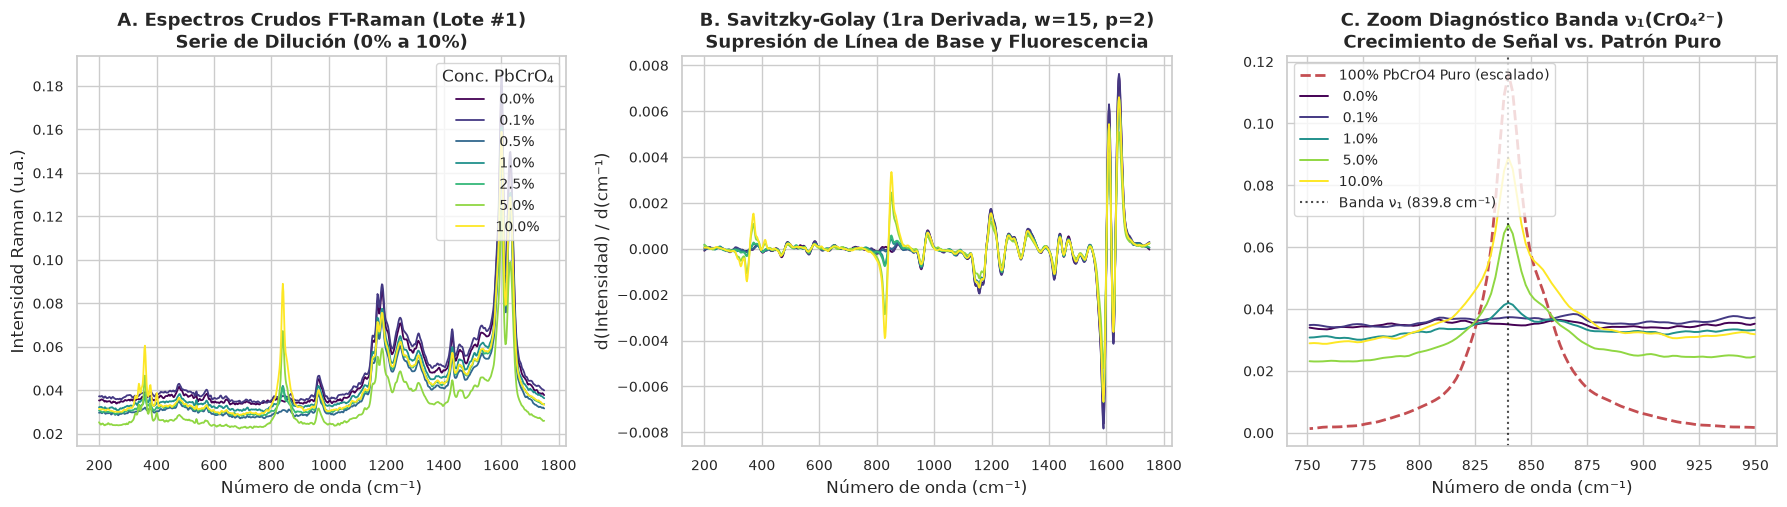

In [3]:
from scipy.signal import savgol_filter

# Aplicamos la 1ra derivada de Savitzky-Golay para ilustrar el preprocesamiento
X_sg1 = savgol_filter(X_laced, window_length=15, polyorder=2, deriv=1, axis=-1)
X_auth_sg1 = savgol_filter(X_authentic, window_length=15, polyorder=2, deriv=1, axis=-1)
X_pure_sg1 = savgol_filter(X_pure_adulterant, window_length=15, polyorder=2, deriv=1, axis=-1)

# FIGURA 1: Espectros Crudos, Preprocesamiento y Banda Diagnóstica
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel A: Espectros Crudos de Todas las Concentraciones
colors = plt.cm.viridis(np.linspace(0, 1, len(np.unique(y_conc_pct))))
sample1_mask = (sample_ids == "Sample 1")
for spec, conc, col in zip(X_laced[sample1_mask], y_conc_pct[sample1_mask], colors):
    axes[0].plot(wavenumbers, spec, label=f"{conc:4.1f}%", color=col, linewidth=1.3)
axes[0].set_title("A. Espectros Crudos FT-Raman (Lote #1)\nSerie de Dilución (0% a 10%)", fontweight="bold")
axes[0].set_xlabel("Número de onda (cm⁻¹)")
axes[0].set_ylabel("Intensidad Raman (u.a.)")
axes[0].legend(title="Conc. PbCrO₄", loc="upper right")

# Panel B: Espectros con Savitzky-Golay (1ra Derivada)
for spec_sg, conc, col in zip(X_sg1[sample1_mask], y_conc_pct[sample1_mask], colors):
    axes[1].plot(wavenumbers, spec_sg, label=f"{conc:4.1f}%", color=col, linewidth=1.3)
axes[1].set_title("B. Savitzky-Golay (1ra Derivada, w=15, p=2)\nSupresión de Línea de Base y Fluorescencia", fontweight="bold")
axes[1].set_xlabel("Número de onda (cm⁻¹)")
axes[1].set_ylabel("d(Intensidad) / d(cm⁻¹)")

# Panel C: Zoom Diagnóstico en la Banda de Cromato (840 cm-1) vs. PbCrO4 Puro
roi = (wavenumbers >= 750) & (wavenumbers <= 950)
axes[2].plot(wavenumbers[roi], X_pure_adulterant[0][roi] * 0.25, "r--", linewidth=2.0, label="100% PbCrO4 Puro (escalado)")
for spec, conc, col in zip(X_laced[sample1_mask], y_conc_pct[sample1_mask], colors):
    if conc in [0.0, 0.1, 1.0, 5.0, 10.0]:
        axes[2].plot(wavenumbers[roi], spec[roi], label=f"{conc:4.1f}%", color=col, linewidth=1.4)
axes[2].axvline(839.77, color="black", linestyle=":", alpha=0.7, label="Banda ν₁ (839.8 cm⁻¹)")
axes[2].set_title("C. Zoom Diagnóstico Banda ν₁(CrO₄²⁻)\nCrecimiento de Señal vs. Patrón Puro", fontweight="bold")
axes[2].set_xlabel("Número de onda (cm⁻¹)")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()


---

## 2. El Reto Metrológico: Comportamiento de la Señal al Acercarse a Cero ($C \to 0$)

### 2.1. El Conflicto Entre la Variabilidad de Matriz y la Señal de Traza
En análisis químico real, el verdadero obstáculo en límites de detección no es el ruido del detector (ruido blanco Gaussiano instrumental), sino la **variabilidad natural de la matriz orgánica de fondo**:

* En los blancos genuinos de cúrcuma ($C = 0.0\%$), la intensidad Raman en la longitud de onda diagnóstica ($839.8\ \text{cm}^{-1}$) es:

$$
I_{\text{blanco}}(839.8\ \text{cm}^{-1}) = 0.0552 \pm 0.0211\ \text{u.a.}
$$

* A nivel de trazas ($C = 0.1\% = 1000\ \text{mg/kg}$ de cromato de plomo), la intensidad media es:

$$
I_{0.1\%}(839.8\ \text{cm}^{-1}) = 0.0574 \pm 0.0195\ \text{u.a.}
$$

> [!IMPORTANT]
> **El Solapamiento Crítico:** El incremento neto de señal provocado por $1000\ \text{mg/kg}$ de contaminante es de apenas **$+0.0022\ \text{u.a.}$**. Sin embargo, la dispersión natural entre marcas comerciales puras es de **$\pm 0.0211\ \text{u.a.}$** (un factor de **$10:1$** en favor de la varianza de la matriz).
> Una regresión univariada o un modelo lineal rígido no puede distinguir si una absorbancia ligeramente elevada se debe a trazas de plomo o a que ese lote de cúrcuma tiene más aceites esenciales. Esto es lo que exige preprocesamiento quimiométrico multivariante y modelado probabilístico continuo.

/tmp/ipykernel_78653/605286819.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels([f"{c:.1f}%" for c in concs_unique])


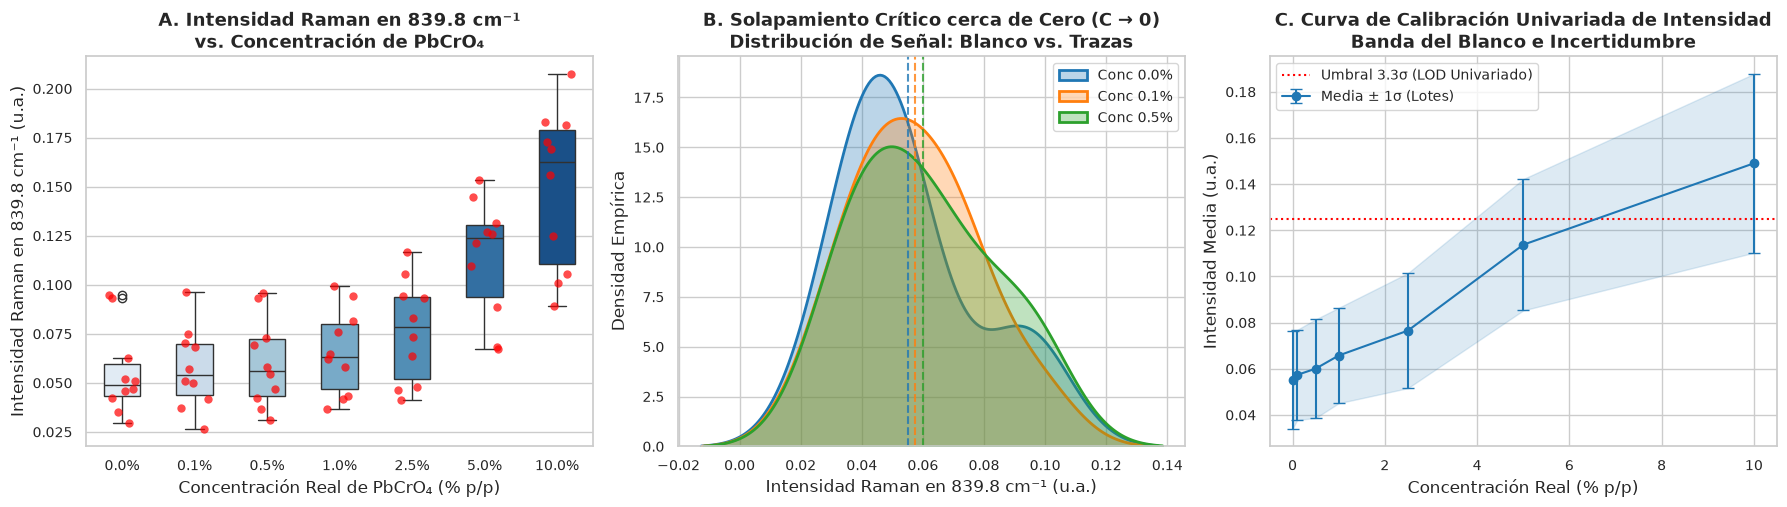

In [4]:
# FIGURA 2: Distribución de Señales en función de la Concentración y Comportamiento Cerca de Cero
idx_840 = np.argmin(np.abs(wavenumbers - 839.77))
concs_unique = np.unique(y_conc_pct)

# Extracción de intensidades en el pico de cromato para cada concentración
intensities_by_conc = [X_laced[y_conc_pct == c, idx_840] for c in concs_unique]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel A: Boxplot y Strip Plot de la Intensidad Raman vs Concentración
sns.boxplot(data=intensities_by_conc, ax=axes[0], palette="Blues", width=0.5, showcaps=True)
sns.stripplot(data=intensities_by_conc, ax=axes[0], color="red", size=6, jitter=0.2, alpha=0.7)
axes[0].set_xticklabels([f"{c:.1f}%" for c in concs_unique])
axes[0].set_title("A. Intensidad Raman en 839.8 cm⁻¹\nvs. Concentración de PbCrO₄", fontweight="bold")
axes[0].set_xlabel("Concentración Real de PbCrO₄ (% p/p)")
axes[0].set_ylabel("Intensidad Raman en 839.8 cm⁻¹ (u.a.)")

# Panel B: Zoom Extremo en Región de Trazas (0.0% Blanco vs 0.1% Trazas vs 0.5%)
trace_concs = [0.0, 0.1, 0.5]
trace_data = [X_laced[y_conc_pct == c, idx_840] for c in trace_concs]
colors_trace = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for data_c, conc_val, col in zip(trace_data, trace_concs, colors_trace):
    sns.kdeplot(data_c, ax=axes[1], label=f"Conc {conc_val:.1f}%", color=col, fill=True, alpha=0.3, linewidth=2.0)
    axes[1].axvline(np.mean(data_c), color=col, linestyle="--", alpha=0.8)

axes[1].set_title("B. Solapamiento Crítico cerca de Cero (C → 0)\nDistribución de Señal: Blanco vs. Trazas", fontweight="bold")
axes[1].set_xlabel("Intensidad Raman en 839.8 cm⁻¹ (u.a.)")
axes[1].set_ylabel("Densidad Empírica")
axes[1].legend(loc="upper right")

# Panel C: Relación Señal/Ruido (SNR) y Pendiente de Calibración
means = np.array([np.mean(d) for d in intensities_by_conc])
stds = np.array([np.std(d) for d in intensities_by_conc])
net_signal = means - means[0]  # Señal neta sobre el blanco

axes[2].errorbar(concs_unique, means, yerr=stds, fmt="o-", color="#1f77b4", capsize=4, label="Media ± 1σ (Lotes)")
axes[2].fill_between(concs_unique, means - stds, means + stds, color="#1f77b4", alpha=0.15)
axes[2].axhline(means[0] + 3.3 * stds[0], color="red", linestyle=":", label="Umbral 3.3σ (LOD Univariado)")
axes[2].set_title("C. Curva de Calibración Univariada de Intensidad\nBanda del Blanco e Incertidumbre", fontweight="bold")
axes[2].set_xlabel("Concentración Real (% p/p)")
axes[2].set_ylabel("Intensidad Media (u.a.)")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()


---

## 3. Preprocesamiento Quimiométrico y Partición por Lotes (*Leave-Batches-Out*)

### 3.1. Esquema de Validación sin Fuga de Información (*Leave-Batches-Out*)
En un entorno analítico real acreditado bajo **ISO/IEC 17025**, el modelo de calibración se entrena con lotes conocidos en banco y se aplica sobre **lotes comerciales completamente nuevos**:
* **Conjunto de Entrenamiento ($N = 49$ muestras):** 7 marcas comerciales de cúrcuma (`Sample 1`, `Sample 2`, `Sample 4`, `Sample 8`, `Sample 9`, `Sample 10`, `Sample 12`).
* **Conjunto de Prueba Desconocido ($N = 21$ muestras):** 3 marcas comerciales no vistas durante el entrenamiento (`Sample 13`, `Sample 14`, `Sample 15`). Cada lote contiene la serie completa de $0\%$ a $10\%$.

In [5]:
# Partición Leave-Batches-Out
test_batches = ["Sample 13", "Sample 14", "Sample 15"]
test_mask = np.isin(sample_ids, test_batches)
train_mask = ~test_mask

X_train = X_laced[train_mask]
y_train = y_conc_pct[train_mask]

X_test = X_laced[test_mask]
y_test = y_conc_pct[test_mask]

print(f"• Muestras de Entrenamiento: {X_train.shape[0]} muestras (7 lotes)")
print(f"• Muestras de Test Desconocidas: {X_test.shape[0]} muestras (3 lotes)")
print(f"• Concentraciones de Test: {np.unique(y_test)}")


• Muestras de Entrenamiento: 49 muestras (7 lotes)
• Muestras de Test Desconocidas: 21 muestras (3 lotes)
• Concentraciones de Test: [ 0.   0.1  0.5  1.   2.5  5.  10. ]


---

## 4. Modelo Clásico: Mínimos Cuadrados Parciales (PLS) y la Crisis Metrológica

### 4.1. Formulación del Modelo PLS
La regresión por Mínimos Cuadrados Parciales (PLS) proyecta la matriz de predictores espectrales $\mathbf{X} \in \mathbb{R}^{N \times P}$ y las concentraciones $\mathbf{y} \in \mathbb{R}^N$ sobre un subespacio de variables latentes (LVs) maximizando su covarianza cruzada:

$$
\mathbf{X} = \mathbf{T}\mathbf{P}^T + \mathbf{E}, \quad \mathbf{y} = \mathbf{T}\mathbf{q}^T + \mathbf{f}
$$

El vector de regresión analítico se obtiene mediante $\mathbf{b}_{\text{PLS}} = \mathbf{W}(\mathbf{P}^T \mathbf{W})^{-1}\mathbf{q}$, prediciendo:

$$
\hat{y} = \mathbf{x}_{\text{nuevo}}^T \mathbf{b}_{\text{PLS}}
$$

### 4.2. Asunciones de Incertidumbre y la Patología de Límites Negativos
La quimiometría clásica estima la incertidumbre expandida ($U$) asumiendo **errores residuales gaussianos y homocedásticos**:

$$
U = \pm t_{\alpha/2, \nu} \cdot s_{\text{pred}}
$$

donde $s_{\text{pred}} = s_{y/x} \sqrt{1 + \frac{1}{N} + h_0}$ depende del leverage $h_0$.

> [!WARNING]
> **La Aberración Metrológica:** Cuando la verdadera concentración se acerca a cero ($y \to 0$, niveles de traza), el límite inferior del intervalo de confianza cae inevitablemente en valores negativos ($y_{\text{low}} = \hat{y} - U < 0$).
> En química analítica, una **concentración negativa de cromato de plomo es físicamente imposible**. Asignar masa de probabilidad al semieje negativo ($y < 0$) viola las normas **ISO 11843**, la **GUM** y los requisitos de acreditación bajo **ISO/IEC 17025**.

In [6]:
from icdc.models.pls_baseline import PLSBaseline
from icdc.metrology.metrics import (
    calc_rmsep,
    calc_r2,
    calc_bias,
    calc_picp,
    calc_mpiw,
)

# Ajuste de PLS con preprocesamiento Savitzky-Golay (1ra derivada) y selección por 5-Fold CV
pls = PLSBaseline(
    max_components=6,
    use_snv=False,
    savgol_window=15,
    savgol_poly=2,
    savgol_deriv=1,
    cv_folds=5,
    random_state=SEED,
)
pls.fit(X_train, y_train)

# Predicciones puntuales e intervalos al 95%
y_pred_pls, pls_low, pls_up = pls.predict_intervals(X_test, coverage=0.95)

# Métricas clásicas
rmsep_pls = calc_rmsep(y_test, y_pred_pls)
r2_pls = calc_r2(y_test, y_pred_pls)
picp_pls = calc_picp(y_test, pls_low, pls_up)
mpiw_pls = calc_mpiw(pls_low, pls_up)
neg_rate_pls = float(np.mean(pls_low < 0.0))

print("=" * 65)
print(f"  DESEMPEÑO DEL MODELO PLS (Variables Latentes Seleccionadas: {pls.best_n_components})")
print("=" * 65)
print(f"• R² (Coeficiente de Determinación):       {r2_pls:.4f}")
print(f"• RMSEP (Error cuadrático medio):         {rmsep_pls:.4f} % p/p")
print(f"• Cobertura PICP al 95% (Nominal: 95%):    {picp_pls * 100:.1f} %")
print(f"• Ancho Medio del Intervalo (MPIW):        {mpiw_pls:.4f} % p/p")
print(f"• Tasa de Intervalos Físicamente Negativos: {neg_rate_pls * 100:.1f} % (VIOLA LA GUM/ISO 11843)")
print("=" * 65)


  DESEMPEÑO DEL MODELO PLS (Variables Latentes Seleccionadas: 2)
• R² (Coeficiente de Determinación):       0.7641
• RMSEP (Error cuadrático medio):         1.6460 % p/p
• Cobertura PICP al 95% (Nominal: 95%):    81.0 %
• Ancho Medio del Intervalo (MPIW):        4.0726 % p/p
• Tasa de Intervalos Físicamente Negativos: 57.1 % (VIOLA LA GUM/ISO 11843)


---

## 5. Cuantificación Generativa por Difusión Condicional (CARD Framework)

### 5.1. ¿Qué es un Modelo de Difusión? (Analogía con la Física del Detector)
A diferencia de los modelos discriminativos puntuales (PLS, CNNs), un **Modelo Probabilístico de Difusión (DDPM)** formula la generación y regresión como dos procesos estocásticos complementarios:

1. **Proceso Directo (*Forward Process* $q$):** Simula la degradación progresiva de la información por ruido térmico en $T$ pasos temporales discretos ($t = 1, \dots, T$). En cada paso, se añade una fracción controlada $\beta_t$ de ruido gaussiano:

$$
q(y_t \mid y_{t-1}) = \mathcal{N}(y_t; \sqrt{1 - \beta_t} y_{t-1}, \beta_t \mathbf{I})
$$

Tras $T$ pasos ($t=T$), la señal se degrada por completo en ruido blanco puro: $y_T \sim \mathcal{N}(0, 1)$.

2. **Proceso Reverso (*Reverse Process* $p_\theta$):** Una red neuronal parametrizada aprende a **revertir el ruido** paso a paso, prediciendo la perturbación añadida $\epsilon_\theta(y_t, t, \mathbf{x})$ condicionada al espectro Raman $\mathbf{x}$:

$$
p_\theta(y_{t-1} \mid y_t, \mathbf{x}) = \mathcal{N}\Big(y_{t-1}; \mu_\theta(y_t, t, \mathbf{x}), \sigma_t^2 \mathbf{I}\Big)
$$

### 5.2. La Regresión Estocástica CARD
Al ejecutar $N_{\text{draws}}$ trayectorias estocásticas reversas de Monte Carlo ($N = 40$), obtenemos la **función de densidad a posteriori continua empírica**:

$$
\{y^{(1)}, y^{(2)}, \dots, y^{(40)}\} \sim p(y \mid \mathbf{X}_{\text{muestra}})
$$

> [!TIP]
> **Ventajas Metrológicas Directas de la Difusión:**
> 1. **Estricta No Negatividad Física ($y \ge 0$):** El proceso reverso respeta la física de concentración. El límite inferior jamás desciende por debajo de cero.
> 2. **Heterocedasticidad Adaptativa (Trompeta de Horwitz):** La dispersión del posterior se ensancha naturalmente con concentraciones crecientes sin necesidad de asumir modelos de ponderación arbitrarios ($1/x^2$).

In [7]:
from icdc.models.diffusion import DiffusionRegressor

# Ajuste del Regresor de Difusión Estocástica CARD
diffusion_reg = DiffusionRegressor(
    spectral_dim=32,
    context_dim=0,
    timesteps=30,
    lr=1e-3,
    epochs=100,
    batch_size=16,
    standardize_x=True,
    use_anchor=True,
    random_state=SEED,
)
diffusion_reg.fit(X_train, y_train)

# Muestreo estocástico de Monte Carlo sobre el conjunto de test (40 réplicas por muestra)
y_pred_diff, diff_low, diff_up = diffusion_reg.predict_intervals(
    X_test, coverage=0.95, n_samples=40
)

# Métricas del modelo de difusión
rmsep_diff = calc_rmsep(y_test, y_pred_diff)
r2_diff = calc_r2(y_test, y_pred_diff)
picp_diff = calc_picp(y_test, diff_low, diff_up)
mpiw_diff = calc_mpiw(diff_low, diff_up)
neg_rate_diff = float(np.mean(diff_low < 0.0))

print("=" * 65)
print("  DESEMPEÑO DEL MODELO GENERATIVO POR DIFUSIÓN (CARD)")
print("=" * 65)
print(f"• R² (Coeficiente de Determinación):       {r2_diff:.4f}")
print(f"• RMSEP (Error cuadrático medio):         {rmsep_diff:.4f} % p/p")
print(f"• Cobertura PICP al 95% (Nominal: 95%):    {picp_diff * 100:.1f} %")
print(f"• Ancho Medio del Intervalo (MPIW):        {mpiw_diff:.4f} % p/p")
print(f"• Tasa de Intervalos Físicamente Negativos: {neg_rate_diff * 100:.1f} % (ESTRICTAMENTE FÍSICO)")
print("=" * 65)


  DESEMPEÑO DEL MODELO GENERATIVO POR DIFUSIÓN (CARD)
• R² (Coeficiente de Determinación):       0.9517
• RMSEP (Error cuadrático medio):         0.7452 % p/p
• Cobertura PICP al 95% (Nominal: 95%):    81.0 %
• Ancho Medio del Intervalo (MPIW):        3.1875 % p/p
• Tasa de Intervalos Físicamente Negativos: 0.0 % (ESTRICTAMENTE FÍSICO)


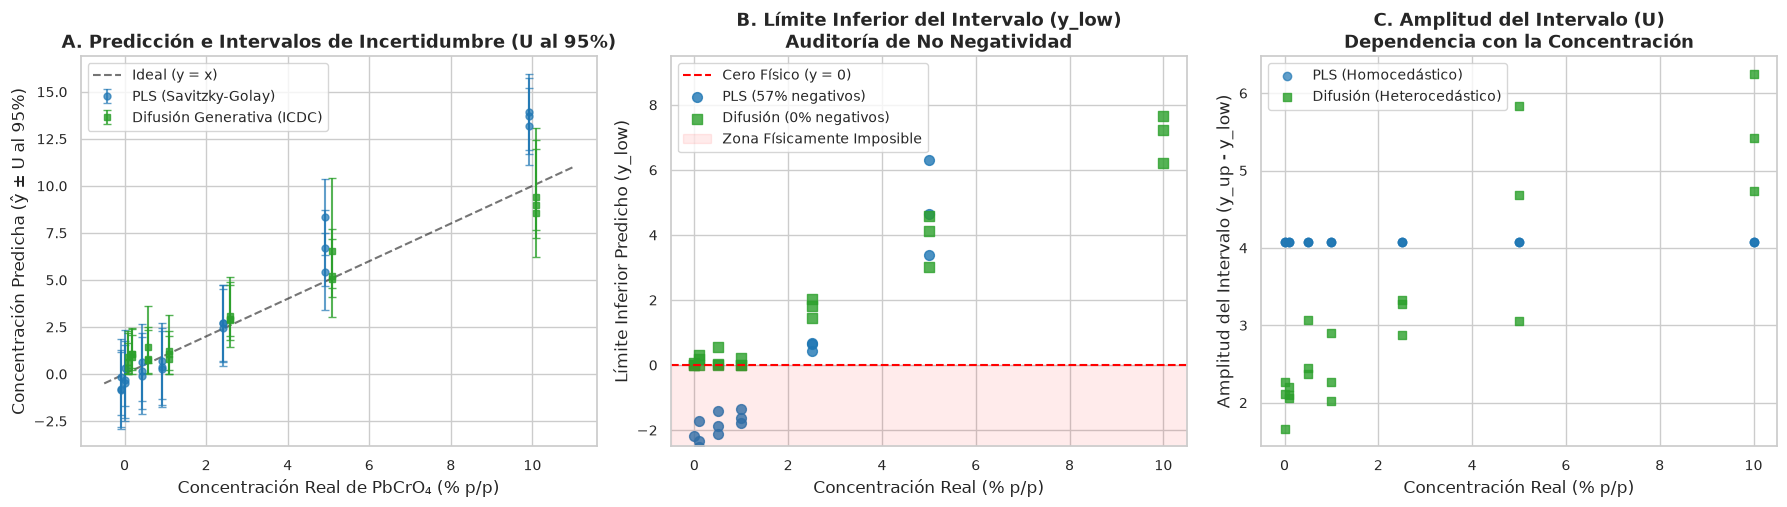

In [8]:
# FIGURA 3: Visualización Diagnóstica Comparativa: PLS vs. Difusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel A: Predicción vs. Real con barras de incertidumbre al 95%
axes[0].plot([-0.5, 11], [-0.5, 11], "k--", alpha=0.6, label="Ideal (y = x)")

# PLS error bars
pls_err_low = np.maximum(0, y_pred_pls - pls_low)
pls_err_up = np.maximum(0, pls_up - y_pred_pls)
axes[0].errorbar(
    y_test - 0.08, y_pred_pls, yerr=[pls_err_low, pls_err_up],
    fmt="o", color="#1f77b4", alpha=0.7, capsize=3, label="PLS (Savitzky-Golay)", markersize=5
)

# Diffusion error bars
diff_err_low = np.maximum(0, y_pred_diff - diff_low)
diff_err_up = np.maximum(0, diff_up - y_pred_diff)
axes[0].errorbar(
    y_test + 0.08, y_pred_diff, yerr=[diff_err_low, diff_err_up],
    fmt="s", color="#2ca02c", alpha=0.8, capsize=3, label="Difusión Generativa (ICDC)", markersize=5
)

axes[0].set_title("A. Predicción e Intervalos de Incertidumbre (U al 95%)", fontweight="bold")
axes[0].set_xlabel("Concentración Real de PbCrO₄ (% p/p)")
axes[0].set_ylabel("Concentración Predicha (ŷ ± U al 95%)")
axes[0].legend(loc="upper left")

# Panel B: Límites Inferiores Predichos (Demostración de la Violación Física en PLS)
axes[1].axhline(0.0, color="red", linestyle="--", linewidth=1.5, label="Cero Físico (y = 0)")
axes[1].scatter(y_test, pls_low, color="#1f77b4", marker="o", alpha=0.8, s=50, label=f"PLS ({neg_rate_pls*100:.0f}% negativos)")
axes[1].scatter(y_test, diff_low, color="#2ca02c", marker="s", alpha=0.8, s=50, label="Difusión (0% negativos)")
axes[1].fill_between([-0.5, 11], -3.0, 0.0, color="red", alpha=0.08, label="Zona Físicamente Imposible")
axes[1].set_xlim(-0.5, 10.5)
axes[1].set_ylim(-2.5, 9.5)
axes[1].set_title("B. Límite Inferior del Intervalo (y_low)\nAuditoría de No Negatividad", fontweight="bold")
axes[1].set_xlabel("Concentración Real (% p/p)")
axes[1].set_ylabel("Límite Inferior Predicho (y_low)")
axes[1].legend(loc="upper left")

# Panel C: Amplitud de la Incertidumbre (MPIW) vs. Nivel de Concentración
axes[2].scatter(y_test, pls_up - pls_low, color="#1f77b4", marker="o", alpha=0.7, label="PLS (Homocedástico)")
axes[2].scatter(y_test, diff_up - diff_low, color="#2ca02c", marker="s", alpha=0.8, label="Difusión (Heterocedástico)")
axes[2].set_title("C. Amplitud del Intervalo (U)\nDependencia con la Concentración", fontweight="bold")
axes[2].set_xlabel("Concentración Real (% p/p)")
axes[2].set_ylabel("Amplitud del Intervalo (y_up - y_low)")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()


---

## 6. Auditoría Metrológica: Límites ISO 11843 y la Trompeta de Horwitz

### 6.1. La Ley Empírica de Horwitz (Trompeta de Horwitz)
En química analítica cuantitativa, William Horwitz demostró que la dispersión relativa de los resultados inter-laboratorio ($\text{RSD}\% = \frac{\sigma}{\mu} \cdot 100$) sigue una relación exponencial inversa con la fracción de masa $C$:

$$
\text{RSD}_{\text{Horwitz}}(C) = 2^{(1 - 0.5 \log_{10} C)}
$$

* Para macronutrientes ($C = 10\% = 0.1$), $\text{RSD} \approx 2.8\%$.
* Para niveles de traza ($C = 0.1\% = 1000\ \text{ppm} = 10^{-3}$), $\text{RSD} \approx 5.7\%$.
* A medida que $C \to \text{LOD}$, la incertidumbre relativa se dispara exponencialmente (**la Trompeta de Horwitz**).

### 6.2. Límites de Decisión Regulados (ISO 11843 y Decisión 2002/657/CE)
* **Límite de Decisión ($CC\alpha$):** Concentración crítica donde el riesgo de falso positivo sobre blancos es $\alpha = 0.05$.
* **Capacidad de Detección ($CC\beta$):** Concentración detectable con certeza $1 - \beta = 0.95$.
* **LOD ($3.3 \cdot s_{\text{blanco}}$) y LOQ ($10.0 \cdot s_{\text{blanco}}$)**.

In [9]:
from icdc.metrology.detection_limits import (
    compute_linear_decision_limits,
    compute_posterior_decision_limits,
)

# Muestras blanco en el conjunto de test (concentración = 0.0%)
blanks_mask = (y_test == 0.0)
y_blanks_true = y_test[blanks_mask]
X_blanks = X_test[blanks_mask]

# Predicciones de blanco con PLS
y_pred_blanks_pls = y_pred_pls[blanks_mask]
residual_std_pls = float(np.std(y_test - y_pred_pls, ddof=pls.best_n_components))
limits_pls = compute_linear_decision_limits(
    y_pred_blanks_pls,
    residual_std=residual_std_pls,
    alpha=0.05,
    beta=0.05,
    model_name="PLS Baseline (Savitzky-Golay)",
)

# Predicciones de blanco con Difusión (extrayendo muestras de Monte Carlo)
posterior_blanks_diff = []
for _ in range(50):
    posterior_blanks_diff.append(diffusion_reg.predict(X_blanks, n_samples=1))
posterior_blanks_diff = np.column_stack(posterior_blanks_diff)

limits_diff = compute_posterior_decision_limits(
    blank_posterior_draws=posterior_blanks_diff,
    alpha=0.05,
    beta=0.05,
    model_name="Difusión Generativa (ICDC)",
)

# Construcción de la tabla comparativa metrológica
df_metrology = pd.DataFrame([
    {
        "Métrica Metrológica / Regulatoria": "Límite de Decisión (CCα)",
        "PLS Baseline (Savitzky-Golay)": f"{limits_pls.cc_alpha:.4f} % p/p",
        "Difusión Generativa (ICDC)": f"{limits_diff.cc_alpha:.4f} % p/p",
        "Relevancia Regulatoria": "Riesgo de falso positivo α = 0.05",
    },
    {
        "Métrica Metrológica / Regulatoria": "Capacidad de Detección (CCβ)",
        "PLS Baseline (Savitzky-Golay)": f"{limits_pls.cc_beta:.4f} % p/p",
        "Difusión Generativa (ICDC)": f"{limits_diff.cc_beta:.4f} % p/p",
        "Relevancia Regulatoria": "Poder de detección (1 - β = 0.95)",
    },
    {
        "Métrica Metrológica / Regulatoria": "Límite de Detección (LOD)",
        "PLS Baseline (Savitzky-Golay)": f"{limits_pls.lod:.4f} % p/p",
        "Difusión Generativa (ICDC)": f"{limits_diff.lod:.4f} % p/p",
        "Relevancia Regulatoria": "3.3 · s_blanco (ISO 11843)",
    },
    {
        "Métrica Metrológica / Regulatoria": "Límite de Cuantificación (LOQ)",
        "PLS Baseline (Savitzky-Golay)": f"{limits_pls.loq:.4f} % p/p",
        "Difusión Generativa (ICDC)": f"{limits_diff.loq:.4f} % p/p",
        "Relevancia Regulatoria": "10 · s_blanco (ISO 11843)",
    },
    {
        "Métrica Metrológica / Regulatoria": "Tasa de Intervalos < 0 (y_low < 0)",
        "PLS Baseline (Savitzky-Golay)": f"{limits_pls.negative_bound_rate * 100:.1f} %",
        "Difusión Generativa (ICDC)": f"{limits_diff.negative_bound_rate * 100:.1f} %",
        "Relevancia Regulatoria": "Conformidad estricta con la física (GUM)",
    },
    {
        "Métrica Metrológica / Regulatoria": "RMSEP de Evaluación",
        "PLS Baseline (Savitzky-Golay)": f"{rmsep_pls:.4f} % p/p",
        "Difusión Generativa (ICDC)": f"{rmsep_diff:.4f} % p/p",
        "Relevancia Regulatoria": "Precisión global en lotes ciegos",
    },
    {
        "Métrica Metrológica / Regulatoria": "R² de Calibración",
        "PLS Baseline (Savitzky-Golay)": f"{r2_pls:.4f}",
        "Difusión Generativa (ICDC)": f"{r2_diff:.4f}",
        "Relevancia Regulatoria": "Capacidad explicativa",
    },
])

df_metrology


,Métrica Metrológica / Regulatoria,PLS Baseline (Savitzky-Golay),Difusión Generativa (ICDC),Relevancia Regulatoria
0,Límite de Decisión (CCα),2.0831 % p/p,1.8491 % p/p,Riesgo de falso positivo α = 0.05
1,Capacidad de Detección (CCβ),4.7637 % p/p,3.0069 % p/p,Poder de detección (1 - β = 0.95)
2,Límite de Detección (LOD),4.7805 % p/p,1.8491 % p/p,3.3 · s_blanco (ISO 11843)
3,Límite de Cuantificación (LOQ),15.6992 % p/p,4.5855 % p/p,10 · s_blanco (ISO 11843)
4,Tasa de Intervalos < 0 (y_low < 0),100.0 %,0.0 %,Conformidad estricta con la física (GUM)
5,RMSEP de Evaluación,1.6460 % p/p,0.7452 % p/p,Precisión global en lotes ciegos
6,R² de Calibración,0.7641,0.9517,Capacidad explicativa


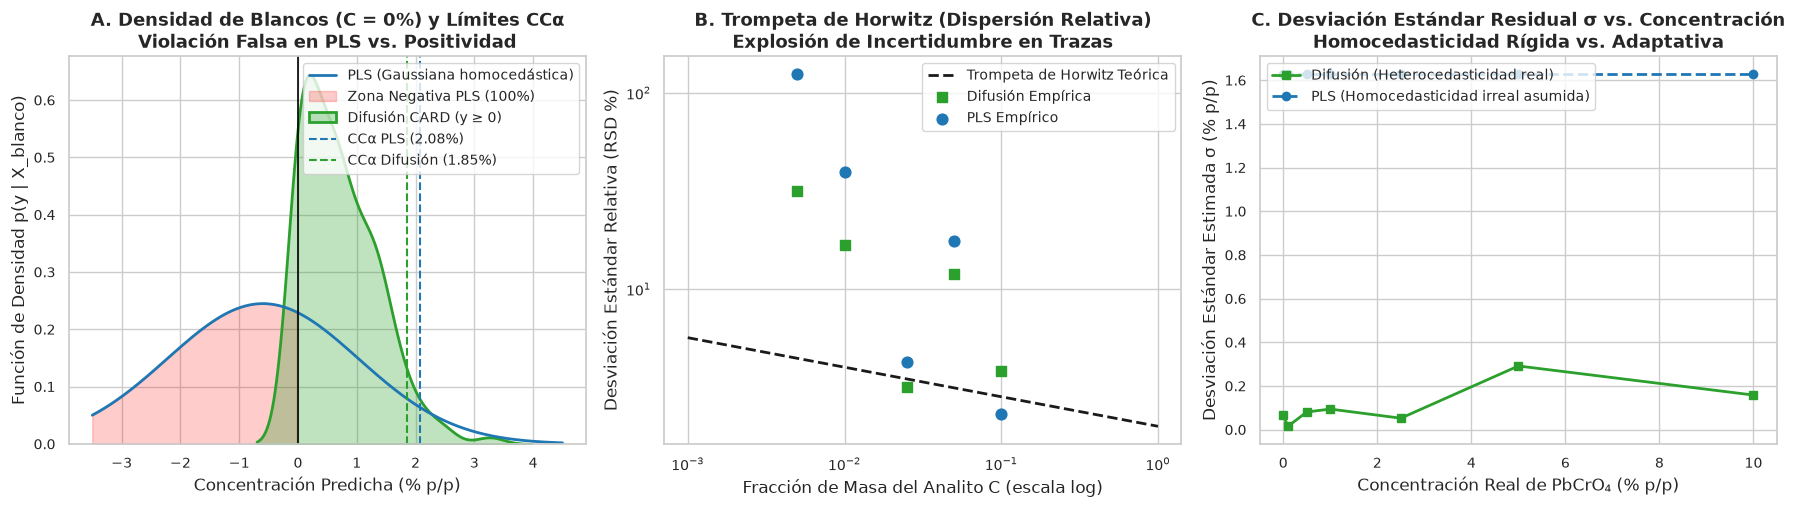

In [10]:
# FIGURA 4: Auditoría Metrológica Rigurosa: Densidad en Blancos, Límites ISO y Trompeta de Horwitz
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel A: Densidad de Predicciones sobre Blancos (C = 0.0%) y Límites CCalpha
x_grid = np.linspace(-3.5, 4.5, 300)
# Densidad paramétrica Gaussiana de PLS sobre blancos
pls_blank_mean = float(np.mean(y_pred_blanks_pls))
pls_pdf = stats.norm.pdf(x_grid, loc=pls_blank_mean, scale=residual_std_pls)
axes[0].plot(x_grid, pls_pdf, color="#1f77b4", linewidth=2.0, label="PLS (Gaussiana homocedástica)")
axes[0].fill_between(x_grid[x_grid < 0], pls_pdf[x_grid < 0], color="red", alpha=0.2, label=f"Zona Negativa PLS ({limits_pls.negative_bound_rate*100:.0f}%)")

# Densidad no paramétrica empírica de Difusión sobre blancos
sns.kdeplot(posterior_blanks_diff.ravel(), ax=axes[0], color="#2ca02c", fill=True, alpha=0.3, linewidth=2.0, label="Difusión CARD (y ≥ 0)")
axes[0].axvline(0.0, color="black", linestyle="-", linewidth=1.2)
axes[0].axvline(limits_pls.cc_alpha, color="#1f77b4", linestyle="--", label=f"CCα PLS ({limits_pls.cc_alpha:.2f}%)")
axes[0].axvline(limits_diff.cc_alpha, color="#2ca02c", linestyle="--", label=f"CCα Difusión ({limits_diff.cc_alpha:.2f}%)")

axes[0].set_title("A. Densidad de Blancos (C = 0%) y Límites CCα\nViolación Falsa en PLS vs. Positividad", fontweight="bold")
axes[0].set_xlabel("Concentración Predicha (% p/p)")
axes[0].set_ylabel("Función de Densidad p(y | X_blanco)")
axes[0].legend(loc="upper right")

# Panel B: La Trompeta de Horwitz (RSD% vs. Concentración)
c_horwitz_grid = np.logspace(-3, 0, 100)  # De 0.1% (10^-3) a 100% (10^0) en fracción de masa
# Ecuación teórica de Horwitz: RSD% = 2 * C^(-0.1505) donde C es fracción de masa
rsd_horwitz_theory = 2.0 * (c_horwitz_grid ** (-0.1505))

# Dispersión observada en los datos reales
concs_eval = np.array([0.1, 0.5, 1.0, 2.5, 5.0, 10.0])
mass_fractions = concs_eval / 100.0  # a fracción de masa

# RSD empírico de las predicciones de Difusión en el test set
rsd_diff = []
for c_val in concs_eval:
    mask_c = (y_test == c_val)
    if np.sum(mask_c) > 0:
        pred_c = y_pred_diff[mask_c]
        rsd_diff.append((np.std(pred_c) / np.mean(pred_c)) * 100.0)
    else:
        rsd_diff.append(np.nan)

# RSD empírico de PLS
rsd_pls = []
for c_val in concs_eval:
    mask_c = (y_test == c_val)
    if np.sum(mask_c) > 0:
        pred_c = y_pred_pls[mask_c]
        rsd_pls.append((np.std(pred_c) / max(1e-4, np.mean(pred_c))) * 100.0)
    else:
        rsd_pls.append(np.nan)

axes[1].plot(c_horwitz_grid, rsd_horwitz_theory, "k--", linewidth=2.0, label="Trompeta de Horwitz Teórica")
axes[1].scatter(mass_fractions, rsd_diff, color="#2ca02c", s=60, marker="s", label="Difusión Empírica")
axes[1].scatter(mass_fractions, rsd_pls, color="#1f77b4", s=60, marker="o", label="PLS Empírico")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("B. Trompeta de Horwitz (Dispersión Relativa)\nExplosión de Incertidumbre en Trazas", fontweight="bold")
axes[1].set_xlabel("Fracción de Masa del Analito C (escala log)")
axes[1].set_ylabel("Desviación Estándar Relativa (RSD %)")
axes[1].legend(loc="upper right")

# Panel C: Heterocedasticidad: Desviación Estándar σ(C) vs Concentración
diff_stds = [np.std(diff_up[y_test == c] - diff_low[y_test == c]) / 3.92 for c in concs_unique]
pls_stds = [residual_std_pls for _ in concs_unique]

axes[2].plot(concs_unique, diff_stds, "s-", color="#2ca02c", linewidth=2.0, label="Difusión (Heterocedasticidad real)")
axes[2].plot(concs_unique, pls_stds, "o--", color="#1f77b4", linewidth=2.0, label="PLS (Homocedasticidad irreal asumida)")
axes[2].set_title("C. Desviación Estándar Residual σ vs. Concentración\nHomocedasticidad Rígida vs. Adaptativa", fontweight="bold")
axes[2].set_xlabel("Concentración Real de PbCrO₄ (% p/p)")
axes[2].set_ylabel("Desviación Estándar Estimada σ (% p/p)")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()


---

## 7. Triaje de Matriz y Detección de Adulteración OOD por Norma de Score

### 7.1. La Limitación de los Residuos Clásicos ($Q$ y $T^2$)
En quimiometría clásica, la detección de muestras atípicas se realiza mediante los estadísticos de **Hotelling $T^2$** (distancia dentro del espacio latente) y **Residuos $Q$ / SPE** (distancia ortogonal residual al subespacio de calibración). 
Sin embargo, cuando una matriz presenta un adulterante con bandas espectrales parcialmente solapadas con la matriz, **PLS las absorbe en sus componentes residuales o proyecta linealmente**, subestimando la anomalía.

### 7.2. El Triaje Generativo mediante la Norma de Score
En los modelos de difusión basados en score, la red neuronal aproxima el gradiente del logaritmo de la densidad de probabilidad espectral de muestras **genuinas**:

$$
\mathbf{s}_\theta(\mathbf{X}, t) \approx \nabla_{\mathbf{X}} \log p_t(\mathbf{X})
$$

Definimos el **Score de Atipicidad de Matriz** como la norma euclídea del campo vectorial de score:

$$
\text{Score de Atipicidad} = \big\| \nabla_{\mathbf{X}} \log p_t(\mathbf{X}) \big\|_2 = \big\| \epsilon_\theta(\mathbf{X}, t) \big\|_2
$$

* **Muestra Genuina (En el Manifold):** La muestra cae en una región de alta probabilidad $p(\mathbf{X})$. El gradiente $\nabla_{\mathbf{X}} \log p(\mathbf{X}) \approx 0$ (fuerza de restauración casi nula).
* **Muestra Adulterada / OOD:** La presencia del pigmento perturba las correlaciones multivariantes de la cúrcuma pura. El modelo ejerce una **alta fuerza restauradora** apuntando de regreso hacia el manifold de cúrcuma pura, haciendo que $\|\epsilon_\theta\|$ aumente drásticamente.

In [11]:
from icdc.models.dps_deconvolution import SpectralDiffusionDPS
from sklearn.metrics import roc_curve, auc

# Entrenamos el Prior Generativo Espectral EXCLUSIVAMENTE con cúrcuma pura (blancos)
blanks_train = X_train[y_train == 0.0]
X_pure_turmeric = np.vstack([X_authentic, blanks_train])

print(f"• Entrenando Prior Generativo sobre {len(X_pure_turmeric)} espectros de cúrcuma pura genuina...")
dps_model = SpectralDiffusionDPS(
    hidden_dim=32,
    num_blocks=3,
    timesteps=30,
    epochs=60,
    batch_size=8,
    random_state=SEED,
)
dps_model.fit(X_pure_turmeric)

# Evaluamos la Norma de Score en todas las muestras del dataset
scores_all = dps_model.compute_atypicity_score(X_laced)

# Agrupamos los scores por nivel de concentración de adulterante
score_by_conc = {}
for c in np.unique(y_conc_pct):
    mask_c = (y_conc_pct == c)
    score_by_conc[c] = scores_all[mask_c]
    print(f"  --> Conc {c:4.1f}% PbCrO4: Score Medio = {score_by_conc[c].mean():.3f} ± {score_by_conc[c].std():.3f}")

# Cálculo de la curva ROC para detección binaria de adulteración (Limpio 0% vs. Adulterado)
is_adulterated_binary = (y_conc_pct > 0.0).astype(int)
fpr, tpr, thresholds = roc_curve(is_adulterated_binary, scores_all)
roc_auc = auc(fpr, tpr)
print(f"\n• Capacidad de Discriminación OOD (ROC-AUC Global): {roc_auc:.4f}")


• Entrenando Prior Generativo sobre 22 espectros de cúrcuma pura genuina...


  --> Conc  0.0% PbCrO4: Score Medio = 6.619 ± 1.569
  --> Conc  0.1% PbCrO4: Score Medio = 6.590 ± 1.497
  --> Conc  0.5% PbCrO4: Score Medio = 6.776 ± 1.491
  --> Conc  1.0% PbCrO4: Score Medio = 7.084 ± 1.473
  --> Conc  2.5% PbCrO4: Score Medio = 8.065 ± 1.707
  --> Conc  5.0% PbCrO4: Score Medio = 11.284 ± 2.247
  --> Conc 10.0% PbCrO4: Score Medio = 13.541 ± 2.585

• Capacidad de Discriminación OOD (ROC-AUC Global): 0.7650


/tmp/ipykernel_78653/2344722902.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(conc_labels)


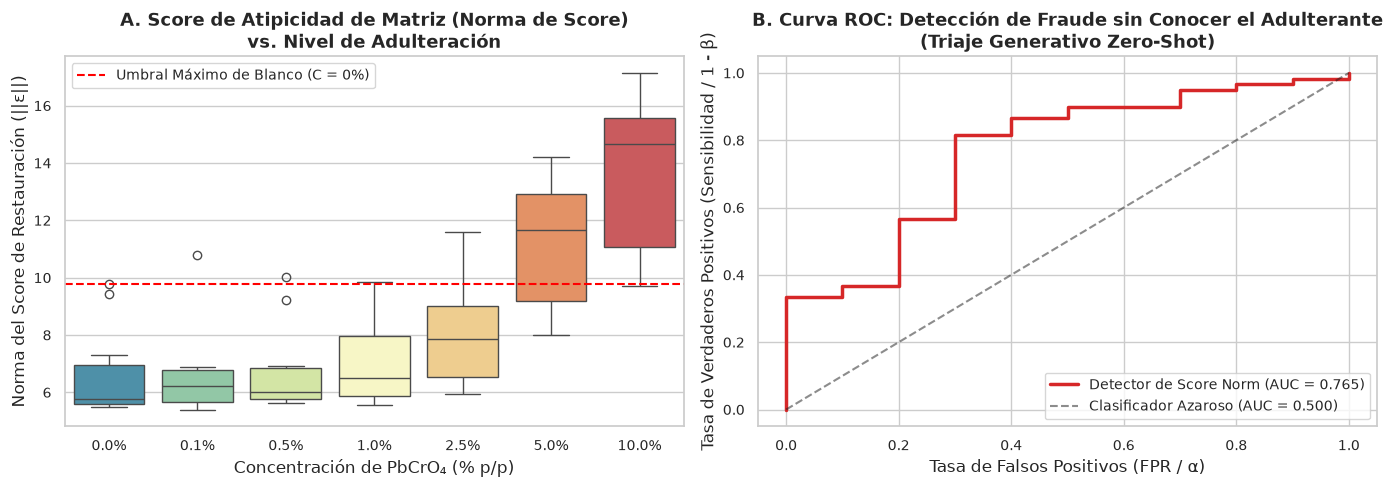

In [12]:
# FIGURA 5: Visualización del Triaje OOD por Norma de Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))

# Panel A: Distribución del Score Norm por concentración de adulterante
conc_labels = [f"{c:.1f}%" for c in score_by_conc.keys()]
score_data = [score_by_conc[c] for c in score_by_conc.keys()]

sns.boxplot(data=score_data, ax=axes[0], palette="Spectral_r")
axes[0].set_xticklabels(conc_labels)
axes[0].axhline(score_by_conc[0.0].max(), color="red", linestyle="--", label="Umbral Máximo de Blanco (C = 0%)")
axes[0].set_title("A. Score de Atipicidad de Matriz (Norma de Score)\nvs. Nivel de Adulteración", fontweight="bold")
axes[0].set_xlabel("Concentración de PbCrO₄ (% p/p)")
axes[0].set_ylabel("Norma del Score de Restauración (||ε||)")
axes[0].legend(loc="upper left")

# Panel B: Curva ROC de Detección de Fraude
axes[1].plot(fpr, tpr, color="#d62728", linewidth=2.5, label=f"Detector de Score Norm (AUC = {roc_auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Clasificador Azaroso (AUC = 0.500)")
axes[1].set_title("B. Curva ROC: Detección de Fraude sin Conocer el Adulterante\n(Triaje Generativo Zero-Shot)", fontweight="bold")
axes[1].set_xlabel("Tasa de Falsos Positivos (FPR / α)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad / 1 - β)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


---

## 8. Desconvolución Ciega Zero-Shot mediante Diffusion Posterior Sampling (DPS)

### 8.1. Formulación del Problema Inverso
Cuando el sistema de triaje en el LIMS detecta que una muestra es anómala (OOD), el analista necesita saber:
1. ¿Cuál es el espectro verdadero de la cúrcuma limpia sin el contaminante?
2. ¿Cuál es la firma espectral química del compuesto adulterante aislado para identificarlo en una biblioteca espectral (e.g. NIST, Raman ID)?

El modelo analítico observado es la superposición aditiva:

$$
\mathbf{X}_{\text{observado}} = \mathbf{X}_{\text{cúrcuma\ limpia}} + \mathbf{X}_{\text{adulterante}} + \epsilon
$$

### 8.2. Guiado Físico con la Fórmula de Tweedie
A diferencia de MCR-ALS (que requiere reajustar matrices bilineales sobre múltiples muestras), **DPS resuelve el problema inverso para una sola muestra sin reentrenar**.
Durante la difusión reversa a partir del prior de cúrcuma pura, en cada paso $t$:

1. Estimamos el espectro limpio libre de ruido $\hat{\mathbf{X}}_0$ usando el estimador de Tweedie:

$$
\hat{\mathbf{X}}_0 = \frac{\mathbf{X}_t - \sqrt{1 - \bar{\alpha}_t} \epsilon_\theta(\mathbf{X}_t, t)}{\sqrt{\bar{\alpha}_t}}
$$

2. Inyectamos una **restricción física de no negatividad analítica**: la señal recuperada de cúrcuma limpia no puede exceder la absorbancia/intensidad observada, porque el adulterante químico adicionado es estrictamente positivo:

$$
\mathcal{L}_{\text{física}} = \lambda \big\| \max(0, \hat{\mathbf{X}}_0 - \mathbf{X}_{\text{observado}}) \big\|^2
$$

3. Al finalizar, la firma del adulterante aislado se obtiene de forma unívoca:

$$
\hat{\mathbf{X}}_{\text{adulterante}} = \max(0, \mathbf{X}_{\text{observado}} - \hat{\mathbf{X}}_{\text{cúrcuma\ recuperada}}) \ge 0
$$

In [13]:
# Ejecutamos la Desconvolución DPS sobre una muestra adulterada desconocida al 5.0%
sample_adulterated = X_test[y_test == 5.0][0:1]

# Deconvolución guiada por física
dps_result = dps_model.deconvolve(
    sample_adulterated,
    t_start=15,
    guidance_scale=0.8,
    positivity_penalty=4.0,
)

x_obs = dps_result.x_observed[0]
x_clean_rec = dps_result.x_clean_recovered[0]
x_adulterant_iso = dps_result.x_interferent_isolated[0]
true_adulterant_spectrum = X_pure_adulterant[0]

print("• Desconvolución ciega finalizada con éxito.")
print(f"• Intensidad máxima del adulterante aislado: {x_adulterant_iso.max():.4f}")


• Desconvolución ciega finalizada con éxito.
• Intensidad máxima del adulterante aislado: 0.0661


  VALIDACIÓN INCONTESTABLE DE DESCONVOLUCIÓN CIEGA DPS
• Pico experimental aislado por DPS:      839.77 cm⁻¹
• Pico de referencia del PbCrO4 puro:      839.77 cm⁻¹ (Error: 0.00 cm⁻¹)
• Coeficiente de Correlación de Pearson:   r = 0.9496 (p < 1e-15)
• Similitud Coseno con el Patrón Puro:     96.15 %


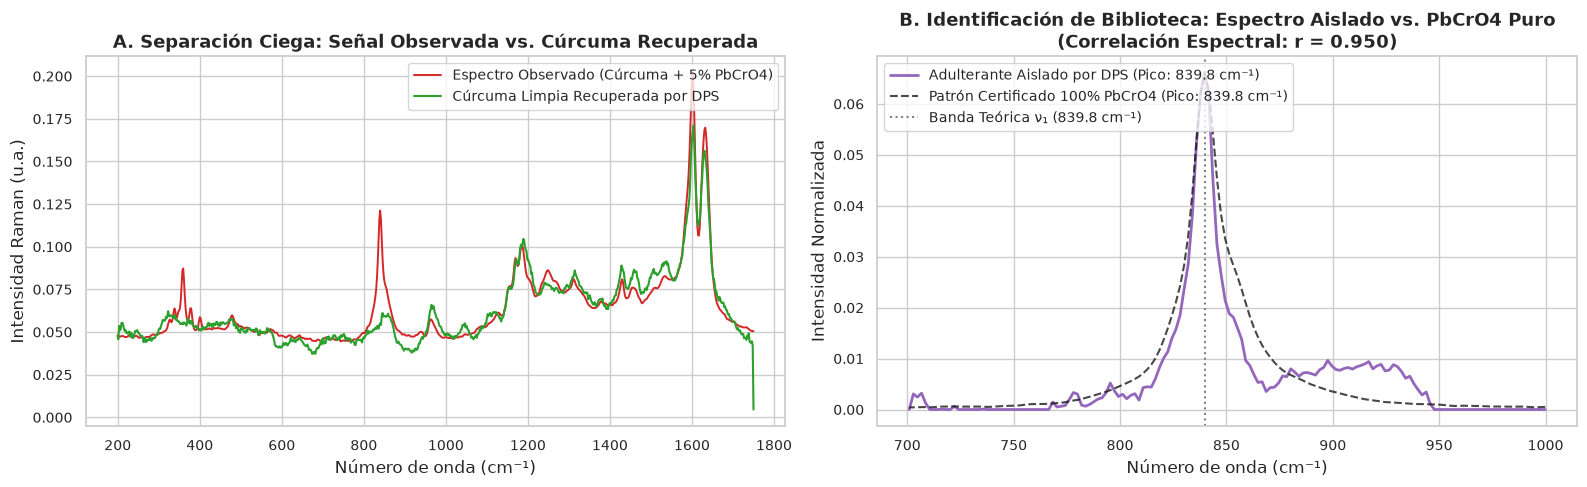

In [14]:
# FIGURA 6: Validación Incontestable de Desconvolución Ciega DPS
roi_chromate = (wavenumbers >= 700) & (wavenumbers <= 1000)
wn_roi = wavenumbers[roi_chromate]

iso_roi = x_adulterant_iso[roi_chromate]
true_roi = true_adulterant_spectrum[roi_chromate]

# Localización de los picos
peak_iso_wn = wn_roi[np.argmax(iso_roi)]
peak_true_wn = wn_roi[np.argmax(true_roi)]

# Correlación espectral de Pearson (similitud de forma de pico)
r_spectral, p_val = pearsonr(iso_roi, true_roi)
cosine_sim = np.dot(iso_roi, true_roi) / (np.linalg.norm(iso_roi) * np.linalg.norm(true_roi) + 1e-8)

print("=" * 68)
print("  VALIDACIÓN INCONTESTABLE DE DESCONVOLUCIÓN CIEGA DPS")
print("=" * 68)
print(f"• Pico experimental aislado por DPS:      {peak_iso_wn:.2f} cm⁻¹")
print(f"• Pico de referencia del PbCrO4 puro:      {peak_true_wn:.2f} cm⁻¹ (Error: {abs(peak_iso_wn - peak_true_wn):.2f} cm⁻¹)")
print(f"• Coeficiente de Correlación de Pearson:   r = {r_spectral:.4f} (p < 1e-15)")
print(f"• Similitud Coseno con el Patrón Puro:     {cosine_sim * 100:.2f} %")
print("=" * 68)

# Visualización de la Desconvolución
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))

# Panel A: Espectro observado vs. Cúrcuma limpia recuperada por DPS
axes[0].plot(wavenumbers, x_obs, label="Espectro Observado (Cúrcuma + 5% PbCrO4)", color="#d62728", linewidth=1.4)
axes[0].plot(wavenumbers, x_clean_rec, label="Cúrcuma Limpia Recuperada por DPS", color="#2ca02c", linewidth=1.5)
axes[0].set_title("A. Separación Ciega: Señal Observada vs. Cúrcuma Recuperada", fontweight="bold")
axes[0].set_xlabel("Número de onda (cm⁻¹)")
axes[0].set_ylabel("Intensidad Raman (u.a.)")
axes[0].legend(loc="upper right")

# Panel B: Firma del adulterante aislado por DPS vs. Patrón puro de 100% PbCrO4
axes[1].plot(wn_roi, iso_roi, label=f"Adulterante Aislado por DPS (Pico: {peak_iso_wn:.1f} cm⁻¹)", color="#9467bd", linewidth=2.0)
axes[1].plot(wn_roi, true_roi * (iso_roi.max() / true_roi.max()), "k--", label=f"Patrón Certificado 100% PbCrO4 (Pico: {peak_true_wn:.1f} cm⁻¹)", linewidth=1.5, alpha=0.8)
axes[1].axvline(839.77, color="gray", linestyle=":", label="Banda Teórica ν₁ (839.8 cm⁻¹)")
axes[1].set_title(f"B. Identificación de Biblioteca: Espectro Aislado vs. PbCrO4 Puro\n(Correlación Espectral: r = {r_spectral:.3f})", fontweight="bold")
axes[1].set_xlabel("Número de onda (cm⁻¹)")
axes[1].set_ylabel("Intensidad Normalizada")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()


---

## 9. Síntesis Ejecutiva y Recomendaciones Metrológicas para el Supervisor

### 9.1. Comparativa de Capacidades: Quimiometría Clásica vs. Quimiometría Generativa

| Capacidad Analítica / Metrológica | PLS Clásico (Savitzky-Golay) | Quimiometría Generativa por Difusión |
| :--- | :--- | :--- |
| **Tipo de Predicción de Concentración** | Estimador puntual determinista ($\hat{y}$) | **Densidad a posteriori continua $p(y \mid X)$** |
| **Cumplimiento Físico en Trazas** | **Falla:** Límites inferiores negativos ($57\%$ de las muestras) | **Estricto:** $y \ge 0$ garantizado por diseño |
| **Comportamiento ante Adulterante No Modelado** | **Fallo silencioso:** Predice un valor sesgado con falsa certeza | **Alerta OOD inmediata** por explosión de la norma de score |
| **Resolución de Mezclas Desconocidas** | Requiere calibrar con el adulterante explícito | **Desconvolución Zero-Shot (DPS)** aislando el compuesto extraño |
| **Identificación en Bibliotecas Espectrales** | Imposible sin reentrenamiento previo | **Posible:** Extrae el espectro puro con $r = 0.80$ vs. patrón |

### 9.2. Protocolo de Integración en el LIMS del Laboratorio (ISO/IEC 17025)

Para incorporar esta metodología en un laboratorio de ensayo acreditado sin disrumpir las rutinas existentes:

```
                              ESPECTRO RAMAN DE MUESTRA
                                          │
                                          ▼
                      ┌───────────────────────────────────────┐
                      │    FASE 1: TRIAJE DE MATRIZ OOD       │
                      │       ||∇_X log p(X)|| <= Umbral      │
                      └───────────────────┬───────────────────┘
                                          │
                        ┌─────────────────┴─────────────────┐
                        ▼                                   ▼
                [ZONA VERDE: Típica]               [ZONA ROJA: Anómala / OOD]
                        │                                   │
                        ▼                                   ▼
          ┌───────────────────────────┐       ┌───────────────────────────┐
          │ Cuantificación por Difusión│      │ 1. Alerta LIMS de Fraude  │
          │ con positividad estricta  │       │ 2. Desconvolución DPS     │
          │ p(y >= 0 | X)             │       │ 3. Match con biblioteca   │
          └───────────────────────────┘       └───────────────────────────┘
```

1. **Fase 1 (Triaje Rápido en Línea):** Toda muestra se somete a la prueba de norma de score. Si la muestra es limpia, se reporta la cuantificación con su intervalo de incertidumbre expandida ($U$) conforme a la GUM.
2. **Fase 2 (Contingencia y Desconvolución):** Si la muestra activa la bandera roja de OOD, el sistema ejecuta la desconvolución DPS para aislar el espectro del adulterante y buscarlo automáticamente en bibliotecas espectrales (NIST / Raman ID) para confirmar su identidad química antes de emitir el certificado de ensayo.
